# Mushroom

## Câu 7. Cây quyết định theo entropy

### Yêu cầu

Xây dựng cây theo information gain bằng criterion="entropy" như hướng dẫn ID3; dự đoán, đánh giá bằng ma trận nhầm lẫn, accuracy, precision, recall và biểu diễn cây.

### Dữ liệu và phương pháp

Thuộc tính quyết định: class. Sử dụng toàn bộ dữ liệu được cung cấp. Chia huấn luyện 70%, kiểm thử 30%, random_state=42 theo đề. Chỉ số được trình bày theo từng lớp; precision/recall không xác định do mẫu số bằng 0 được quy ước bằng 0 và nêu rõ các lớp không được dự đoán.

In [1]:
print("Đặng Ngọc Hiếu - 6451071024")

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

ROOT = Path.cwd()
while not (ROOT / "datasets").is_dir():
    if (ROOT / "6451071024_Lab2" / "datasets").is_dir():
        ROOT = ROOT / "6451071024_Lab2"
        break
    if ROOT == ROOT.parent:
        raise FileNotFoundError("Không tìm thấy thư mục datasets của LAB2.")
    ROOT = ROOT.parent
pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid", font="DejaVu Sans")


raw = pd.read_csv(ROOT / "datasets/mushroom/mushrooms.csv")
TARGET = "class"
if TARGET not in raw or raw.empty or raw.isna().any().any():
    raise ValueError("Kiểm tra Mushroom: cần cột class và các ô dữ liệu được cung cấp.")
if not set(raw[TARGET].unique()).issubset({"p", "e"}):
    raise ValueError("Nhãn Mushroom phải là p hoặc e.")
# Giữ ? là mức chưa xác định của stalk-root; đề bài này không yêu cầu xóa dòng.
data = raw.copy()


Đặng Ngọc Hiếu - 6451071024


In [2]:
print("Đặng Ngọc Hiếu - 6451071024")

features = data.drop(columns=TARGET)
labels = data[TARGET]


Đặng Ngọc Hiếu - 6451071024


In [3]:
print("Đặng Ngọc Hiếu - 6451071024")

non_numeric = features.select_dtypes(exclude=["number", "bool"]).columns.tolist()
# uint8 lưu đúng 0/1 với một byte cho mỗi phần tử one-hot.
features_onehot = pd.get_dummies(features, columns=non_numeric, dtype="uint8")


Đặng Ngọc Hiếu - 6451071024


In [4]:
print("Đặng Ngọc Hiếu - 6451071024")

from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    features_onehot, labels, test_size=0.3, random_state=42)

if X_train.empty or X_test.empty:
    raise ValueError("Tập huấn luyện và kiểm thử không được trống.")


Đặng Ngọc Hiếu - 6451071024


Đặng Ngọc Hiếu - 6451071024
Accuracy: 1.0
              precision    recall  f1-score   support

           e     1.0000    1.0000    1.0000      1257
           p     1.0000    1.0000    1.0000      1181

    accuracy                         1.0000      2438
   macro avg     1.0000    1.0000    1.0000      2438
weighted avg     1.0000    1.0000    1.0000      2438



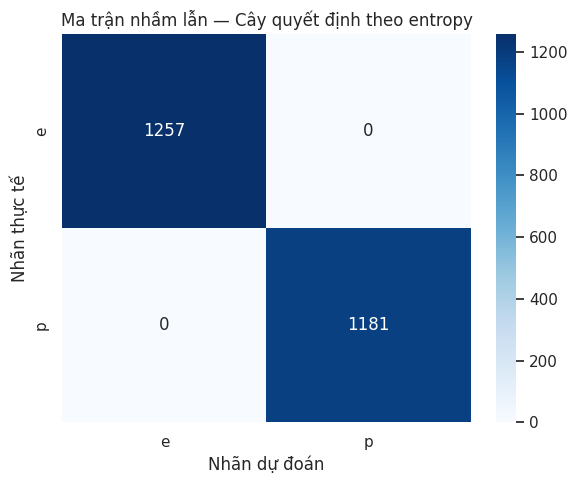

,sample_id,thuc_te,du_doan
0,1971,e,e
1,6654,p,p
2,5606,p,p
3,3332,e,e
4,6988,p,p
5,5761,p,p
6,5798,p,p
7,3064,p,p
8,1811,e,e
9,3422,e,e


In [5]:
print("Đặng Ngọc Hiếu - 6451071024")

from sklearn.tree import DecisionTreeClassifier, plot_tree
model = DecisionTreeClassifier(criterion="entropy", random_state=0)
model.fit(X_train, y_train)
predicted = model.predict(X_test)
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
classes = np.unique(np.concatenate([y_train.to_numpy(), y_test.to_numpy()]))
print("Accuracy:", accuracy_score(y_test, predicted))
print(classification_report(y_test, predicted, labels=classes,
    digits=4, zero_division=0))
# Nêu rõ trường hợp chỉ số precision bằng 0 vì lớp không được dự đoán.
missing_predictions = np.setdiff1d(classes, np.unique(predicted))
if len(missing_predictions):
    print("Các lớp không có dự đoán; precision quy ước bằng 0:", missing_predictions)
cm = confusion_matrix(y_test, predicted, labels=classes)
plt.figure(figsize=(max(6,len(classes)), max(5,len(classes)*0.8)))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=classes, yticklabels=classes)
plt.title("Ma trận nhầm lẫn — Cây quyết định theo entropy")
plt.xlabel("Nhãn dự đoán")
plt.ylabel("Nhãn thực tế")
plt.tight_layout()
plt.show()
plt.close()
output = ROOT / "Bai_6_Mushroom/outputs"
output.mkdir(exist_ok=True)
predictions = pd.DataFrame({"sample_id":y_test.index, "thuc_te":y_test.to_numpy(), "du_doan":predicted})
display(predictions.head(10))
# Lưu đầy đủ dự đoán để câu 10 so sánh, tránh huấn luyện lại mô hình.
predictions.to_csv(output / "Cau07_du_doan.csv", index=False)


Đặng Ngọc Hiếu - 6451071024


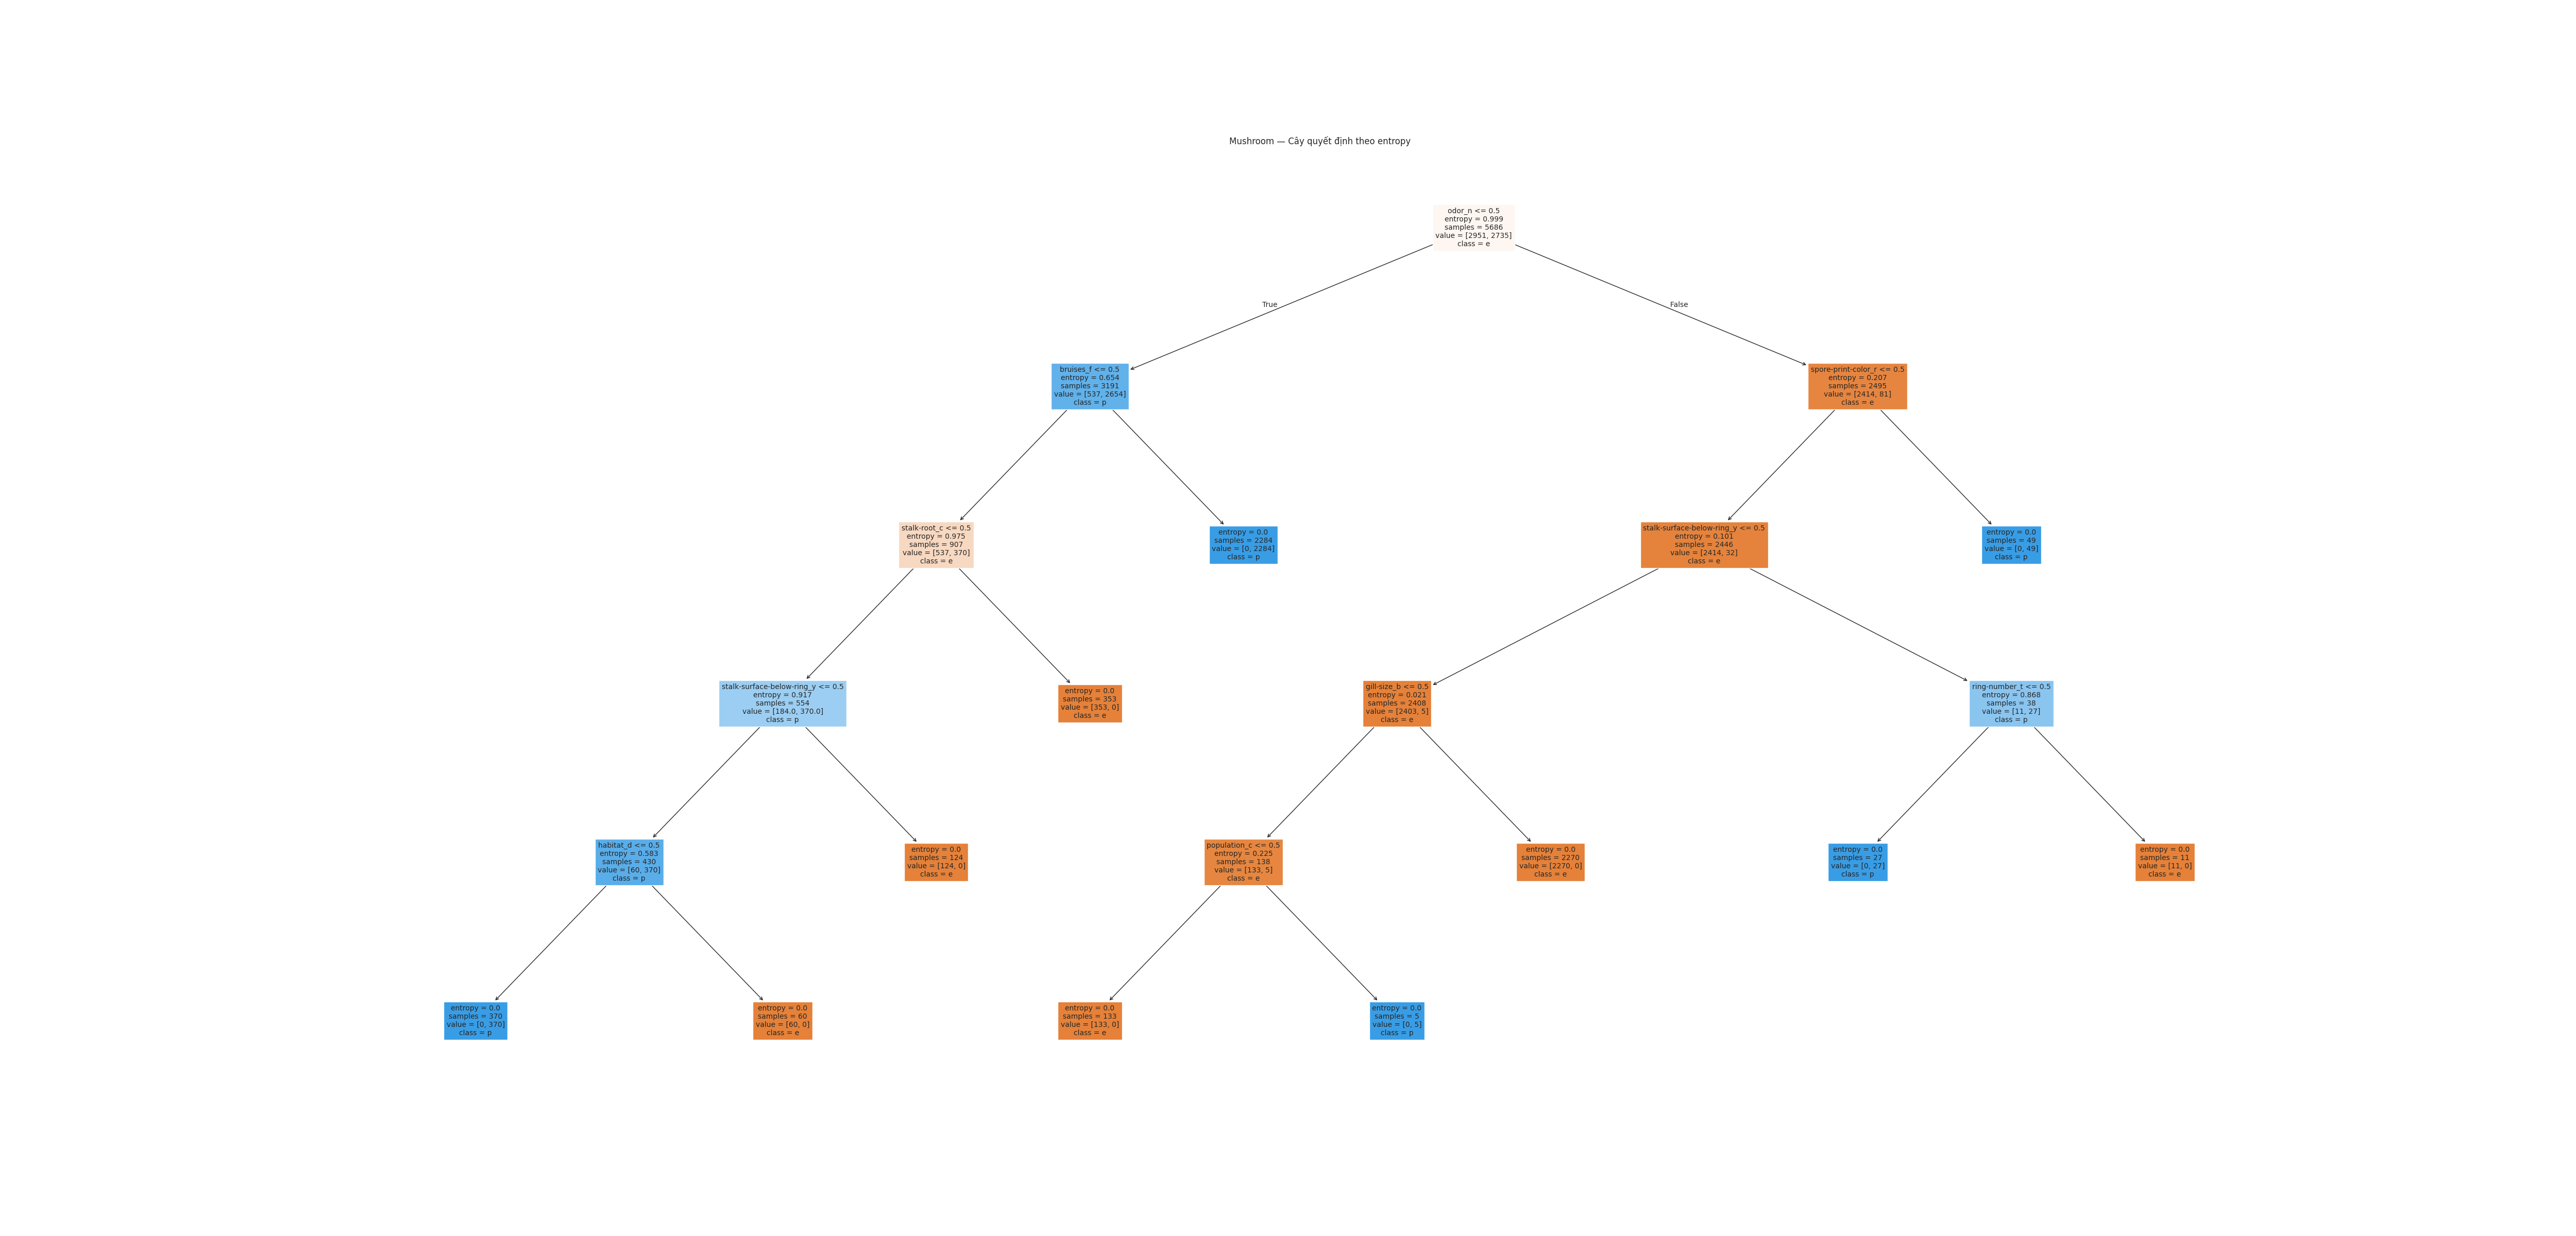

Độ sâu của cây: 5
Số nút lá: 11


In [6]:
print("Đặng Ngọc Hiếu - 6451071024")

# Biểu diễn toàn bộ cây, không đặt giới hạn độ sâu hay cắt nhánh.
fig, ax = plt.subplots(figsize=(50, 24))
plot_tree(model, feature_names=X_train.columns.tolist(),
    class_names=[str(value) for value in model.classes_], filled=True, fontsize=10, ax=ax)
ax.set_title("Mushroom — Cây quyết định theo entropy")
tree_path = output / "Cau07_cay_quyet_dinh.png"
fig.savefig(tree_path, dpi=100)
plt.close(fig)
# Hiển thị PNG đã lưu, tránh dựng lại toàn bộ cây để hiển thị lần thứ hai.
from IPython.display import Image as NotebookImage
display(NotebookImage(filename=str(tree_path)))
print("Độ sâu của cây:", model.get_depth())
print("Số nút lá:", model.get_n_leaves())
